# 08 - Final evaluation (WP-F1)

The configurations chosen in WP-B1, WP-B2 and WP-D3 are run again **on the same folds** and collected in one table, `reports/results_final.csv`. Each one is run on the session-grouped folds (`get_folds`) and on random folds (`get_random_folds`). There is no separate test set: the final result is the mean ± std over the grouped folds.

**This is slightly optimistic.** We chose each configuration by looking at the grouped-CV results and then report it with the same CV, so part of what we measured may come from that choice. With only 3 Bot sessions no data is left over for a truly untouched test, and the differences between the top configurations (below 0.01 broken-subset F1) are smaller than the fold-to-fold std.

## 1. What goes into the table
Selection rule (fixed in advance): the highest broken-subset macro F1 on grouped CV; if the difference is below 0.01, the simpler configuration.

| Row | Source | Broken F1 (grouped) | Why this one |
|---|---|---|---|
| E0: LightGBM, `F_TIMING` | reference | 0.324 | baseline |
| E9: threshold tuning | WP-B1 | 0.340 | best imbalance method (E2 0.326) |
| Set B: LightGBM, `F_FULL` | WP-B2 | 0.339 | G 0.343, A 0.342 and B 0.339 are within 0.01, so the simpler one: B uses no `broken` flag (a recording artefact) and has fewer columns than A |
| D3-11.3: subset models | WP-D3 | 0.343 | best formulation (11.4 hierarchical 0.327) |
| D3-11.5: 4 classes (Bot + DDoS) | WP-D3 | 0.410 | separate row; not comparable with the 5-class rows |
| Binary, Set B | WP-B2 | 0.653 | best binary set (D 0.640) |

**Best 5-class model for the confusion matrices: Set B.** G, D3-11.3, A, E9 and B are all within 0.01 of each other. Two of them depend on the `broken` flag (G uses it as a feature, D3-11.3 routes rows by it), and E9 needs an extra weight search. B is a single model with no extra step and no flag.

Yaşar's LR / DT results are not in the table: `reports/results.csv` is empty and they were not produced with `run_cv`.

## 2. Setup
Imports and named constants. Column lists come only from `src/config.py` (CLAUDE.md rule 7).

In [1]:
import itertools
import os
import sys
import time
sys.path.append('..')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import DATA_PATH, F_FULL, F_TIMING
from src.preprocessing import clean
from imblearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

from src.cv import (CLASSES, append_row, compute_metrics, drop_conflicts, get_folds, get_random_folds,
                    folds_are_grouped, make_confusion, print_fold_table, run_cv, subset_macro_f1)

RANDOM_STATE = 42
OUT_CSV = '../reports/results_final.csv'
FOUR_CLASS_TARGET = 'label_4'   # WP-D3 11.5: Bot merged into DDoS
FEATURE_SET = 'F_TIMING'        # E9 ve D3-11.3'ün bozuk modeli
WEIGHT_GRID = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]   # E9, WP-B1 ile aynı
TUNED_CLASSES = ['Bot', 'DDoS', 'Prob']
BEST_5_CLASS = 'B2_set_B'      # confusion matrix için (bölüm 1)
CLEAN_CLASS_ROWS = ['Benign', 'Dos']   # sağlam alt kümede bulunan gerçek sınıflar

## 3. Load and clean the data, add the 4-class label
Same `clean()` as every package. `label_4` is built exactly as in WP-D3 11.5 (`Bot` -> `DDoS`).

In [2]:
raw = pd.read_csv(DATA_PATH)
df = clean(raw)
df[FOUR_CLASS_TARGET] = df['Label'].replace({'Bot': 'DDoS'})
print(df.shape)
print(df['Label'].value_counts())
print(df[FOUR_CLASS_TARGET].value_counts())

clean: dropped 70 rows with inf/NaN
clean: clipped negative values to 0 in 427 rows


clean: removed 29930 duplicate rows (features + label)


clean: final shape (427044, 63)
(427044, 64)
Label
Benign    233747
Dos       126506
DDoS       50269
Bot         8957
Prob        7565
Name: count, dtype: int64
label_4
Benign    233747
Dos       126506
DDoS       59226
Prob        7565
Name: count, dtype: int64


## 4. Folds
Grouped folds (`get_folds`) and random folds (`get_random_folds`) on the same rows. Both are made from `Label`, so the 4-class and binary rows use exactly the same splits.

In [3]:
folds = get_folds(df)
random_folds = get_random_folds(df)
print_fold_table(df, folds)

Test kısmındaki satır sayıları (sınıf × kat):
        fold_0  fold_1  fold_2
Label                         
Benign   76910   79965   76872
Bot       1757    2585    4615
DDoS     23953   10599   15717
Dos      16482   16711   93313
Prob      2803    2316    2446
Test kısmındaki oturum sayıları (sınıf × kat):
        fold_0  fold_1  fold_2
Label                         
Benign       9       3      11
Bot          1       1       1
DDoS         1       1       2
Dos         19       3       1
Prob         1       1       4


,fold_0,fold_1,fold_2
Label,,,
Benign,76910,79965,76872
Bot,1757,2585,4615
DDoS,23953,10599,15717
Dos,16482,16711,93313
Prob,2803,2316,2446


## 5. Start a fresh results file
`run_cv` appends rows. The old file is removed so that Restart + Run All gives exactly one row per run.

In [4]:
if os.path.exists(OUT_CSV):
    os.remove(OUT_CSV)
    print('Removed old', OUT_CSV)
else:
    print('No old file')

Removed old ../reports/results_final.csv


## 6. Plain LightGBM runs: E0, Set B and the binary task
These three fit into `run_cv()` directly. Each runs twice: on the grouped folds and on the random folds. `run_cv` writes `cv = grouped / random` by itself (it checks whether any session is on both sides).

In [5]:
def make_model():
    """Sabit deney modeli (Kural 5): LightGBM, varsayılan parametreler."""
    return LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)


FOLD_TYPES = [('grouped', folds), ('random', random_folds)]
PLAIN_RUNS = [
    # (experiment, feature_set adı, sütunlar, hedef, not)
    ('E0', 'F_TIMING', F_TIMING, 'Label', 'reference (WP-B1 E0)'),
    ('B2_set_B', 'F_FULL', F_FULL, 'Label', 'best feature set (WP-B2 Set B)'),
    ('binary_B', 'F_FULL', F_FULL, 'label_binary', 'binary task, Set B (WP-B2 10.4)'),
]

results = {}   # (experiment, cv) -> (row, confusion matrix, OOF tahminleri)
for experiment, set_name, cols, target, note in PLAIN_RUNS:
    for cv_name, fold_list in FOLD_TYPES:
        print('=====', experiment, cv_name)
        pipe = Pipeline([('model', make_model())])
        results[(experiment, cv_name)] = run_cv(pipe, df, cols, OUT_CSV, experiment=experiment,
                                                sampler='none', feature_set=set_name, folds=fold_list,
                                                target=target, note=note)

===== E0 grouped
Kat 0


  eğitim: 301069 satır (çelişki atılan: 4070 ) | test: 121905 | fit: 2.5 sn
Kat 1


  eğitim: 309862 satır (çelişki atılan: 5006 ) | test: 112176 | fit: 2.3 sn
Kat 2


  eğitim: 230078 satır (çelişki atılan: 4003 ) | test: 192963 | fit: 1.9 sn


Kat F1'leri: [0.4262 0.5334 0.2952] → 0.4183 ± 0.1193
CSV'ye eklendi: ../reports/results_final.csv


===== E0 random
Kat 0


... (19 outputs left out)

  eğitim: 284267 satır (çelişki atılan: 429 ) | test: 142348 | fit: 0.6 sn
Kat 1


  eğitim: 284331 satır (çelişki atılan: 365 ) | test: 142348 | fit: 0.6 sn
Kat 2


  eğitim: 284260 satır (çelişki atılan: 436 ) | test: 142348 | fit: 0.7 sn


Kat F1'leri: [0.9305 0.9306 0.9325] → 0.9312 ± 0.0011
CSV'ye eklendi: ../reports/results_final.csv


In [6]:
SHOW_COLS = ['experiment', 'cv', 'macro_f1_mean', 'macro_f1_std', 'macro_f1_clean', 'macro_f1_broken',
             'recall_Bot', 'recall_DDoS', 'pred_ms_per_flow']
print(pd.read_csv(OUT_CSV)[SHOW_COLS].round(3).to_string(index=False))

experiment      cv  macro_f1_mean  macro_f1_std  macro_f1_clean  macro_f1_broken  recall_Bot  recall_DDoS  pred_ms_per_flow
        E0 grouped          0.418         0.119           0.512            0.324       0.031        0.713             0.002
        E0  random          0.630         0.005           0.989            0.432       0.046        0.821             0.002
  B2_set_B grouped          0.499         0.052           0.837            0.339       0.033        0.718             0.002
  B2_set_B  random          0.646         0.001           0.999            0.457       0.057        0.833             0.002
  binary_B grouped          0.817         0.058           0.840            0.653         NaN          NaN             0.000
  binary_B  random          0.931         0.001           0.999            0.694         NaN          NaN             0.000


## 7. E9 - threshold tuning (WP-B1)
E9 does not fit into `run_cv()`. The four functions below are **copied unchanged from `notebooks/04_imbalance.ipynb`, section 10** (notebooks cannot import each other). In short: inside each outer training fold, the first inner fold that has all five classes is the inner validation part; Bot/DDoS/Prob weights (0.5-3.0, 216 combinations) are chosen on its broken-subset F1; the E0 model is refitted on the whole outer training fold and the weights are applied to the outer test fold. Metrics come from the `src/cv.py` helpers; `save_e9_row` writes the same columns as `run_cv`.

In [7]:
def apply_weights(proba, classes, weights):
    """Olasılıkları sınıf katsayılarıyla çarpar, en yüksek değerli sınıfı döndürür.

    weights: {sınıf: katsayı}; sözlükte olmayan sınıfların katsayısı 1.
    """
    adjusted = proba.copy()
    for col, class_name in enumerate(classes):
        adjusted[:, col] = adjusted[:, col] * weights.get(class_name, 1.0)
    return np.asarray(classes)[np.argmax(adjusted, axis=1)]


def choose_weights(proba, classes, y_val, broken_val):
    """İç validation'da 216 katsayı kombinasyonunu dener; bozuk F1'i en iyi olanı döndürür.

    Dönüş: (en iyi {sınıf: katsayı} sözlüğü, o kombinasyonun bozuk macro F1'i).
    """
    best_weights = {}
    best_score = -1.0
    for combo in itertools.product(WEIGHT_GRID, repeat=len(TUNED_CLASSES)):
        weights = dict(zip(TUNED_CLASSES, combo))
        pred = apply_weights(proba, classes, weights)
        score = subset_macro_f1(y_val[broken_val], pred[broken_val], CLASSES)
        # Eşitlikte ilk bulunan kalır (grid sırası), böylece sonuç tekrarlanabilir.
        if score > best_score:
            best_score = score
            best_weights = weights
    return best_weights, best_score

In [8]:
def pick_inner_validation(train, inner_folds):
    """İç katlardan, testinde 5 sınıfın hepsi olan ilkini seçer; (iç eğitim, iç validation) döndürür.

    Dış eğitim katında Bot'un 2 oturumu var; 3 iç kattan biri Bot'suz kalır (Adım 6).
    """
    for inner_train_idx, inner_val_idx in inner_folds:
        val_classes = set(train['Label'].iloc[inner_val_idx])
        train_classes = set(train['Label'].iloc[inner_train_idx])
        if val_classes == set(CLASSES) and train_classes == set(CLASSES):
            return train.iloc[inner_train_idx], train.iloc[inner_val_idx]
    raise ValueError('No inner fold contains all five classes')


def run_e9_fold(train):
    """Tek dış kat için E9: iç bölmede katsayı seç, tüm eğitim katında yeniden fit et.

    train: çelişkileri atılmış dış eğitim katı. Dönüş: (fit edilmiş model, seçilen katsayılar).
    """
    train = train.reset_index(drop=True)
    inner_train, inner_val = pick_inner_validation(train, get_folds(train))
    print('  inner train:', len(inner_train), '| inner validation:', len(inner_val),
          '| validation classes:', dict(inner_val['Label'].value_counts()))

    inner_model = make_model().fit(inner_train[F_TIMING], inner_train['Label'])
    proba_val = inner_model.predict_proba(inner_val[F_TIMING])
    weights, val_score = choose_weights(proba_val, inner_model.classes_,
                                        inner_val['Label'].to_numpy(), inner_val['broken'].to_numpy())
    print('  chosen weights:', weights, '| inner broken F1:', round(val_score, 4))

    model = make_model().fit(train[F_TIMING], train['Label'])
    return model, weights

In [9]:
def run_e9(fold_list):
    """E9'u verilen katlarda çalıştırır. (kat F1'leri, OOF tahminleri, süreler, katsayılar) döndürür."""
    y_true = df['Label'].to_numpy()
    oof = np.empty(len(df), dtype=object)
    fold_f1s = []
    fit_times = []
    predict_seconds = 0.0
    chosen = []

    for fold_no, (train_idx, test_idx) in enumerate(fold_list):
        print('Fold', fold_no)
        train = drop_conflicts(df.iloc[train_idx], F_TIMING)   # Kural 4: sadece eğitim katında
        test = df.iloc[test_idx]

        start = time.perf_counter()
        model, weights = run_e9_fold(train)
        fit_times.append(time.perf_counter() - start)

        start = time.perf_counter()
        pred = apply_weights(model.predict_proba(test[F_TIMING]), model.classes_, weights)
        predict_seconds += time.perf_counter() - start

        oof[test_idx] = pred
        fold_f1s.append(subset_macro_f1(y_true[test_idx], pred, CLASSES))
        chosen.append(weights)
        print('  outer test macro F1:', round(fold_f1s[-1], 4))
    return fold_f1s, oof, fit_times, predict_seconds, chosen

In [10]:
def save_e9_row(fold_f1s, oof, fit_times, predict_seconds, chosen, cv_name):
    """E9 sonucunu run_cv ile aynı sütunlarla CSV'ye ekler; (row, cm, OOF) döndürür."""
    y_true = df['Label'].to_numpy()
    metrics = compute_metrics(y_true, oof, df['broken'])
    row = {'experiment': 'E9', 'model': 'LGBMClassifier', 'sampler': 'threshold_tuning',
           'feature_set': FEATURE_SET, 'cv': cv_name,
           'macro_f1_mean': np.mean(fold_f1s), 'macro_f1_std': np.std(fold_f1s, ddof=1),
           'macro_f1_clean': metrics['macro_f1_clean'], 'macro_f1_broken': metrics['macro_f1_broken']}
    for class_name in CLASSES:
        row['recall_' + class_name] = metrics['recall_' + class_name]
    row['bot_ddos_confusion'] = metrics['bot_ddos_confusion']
    row['fit_time_s'] = np.mean(fit_times)
    row['pred_ms_per_flow'] = predict_seconds / len(df) * 1000
    weights_text = ' | '.join(str(w) for w in chosen)
    row['note'] = 'weights chosen on inner validation (broken F1): ' + weights_text

    print('Fold F1s:', np.round(fold_f1s, 4), '->', round(row['macro_f1_mean'], 4), '+-', round(row['macro_f1_std'], 4))
    append_row(row, OUT_CSV)
    return row, make_confusion(y_true, oof), pd.Series(oof, index=df.index)

In [11]:
for cv_name, fold_list in FOLD_TYPES:
    print('=====', 'E9', cv_name)
    e9_output = run_e9(fold_list)
    results[('E9', cv_name)] = save_e9_row(*e9_output, cv_name=cv_name)
print(pd.read_csv(OUT_CSV)[SHOW_COLS].round(3).to_string(index=False))

===== E9 grouped
Fold 0


  inner train: 224931 | inner validation: 76138 | validation classes: {'Benign': np.int64(48375), 'Dos': np.int64(14125), 'DDoS': np.int64(9839), 'Bot': np.int64(2482), 'Prob': np.int64(1317)}


  chosen weights: {'Bot': 3.0, 'DDoS': 1.5, 'Prob': 3.0} | inner broken F1: 0.309


  outer test macro F1: 0.4012
Fold 1


  inner train: 243465 | inner validation: 66397 | validation classes: {'Benign': np.int64(46456), 'DDoS': np.int64(9855), 'Dos': np.int64(7151), 'Bot': np.int64(1617), 'Prob': np.int64(1318)}


  chosen weights: {'Bot': 3.0, 'DDoS': 1.0, 'Prob': 3.0} | inner broken F1: 0.3821


... (13 outputs left out)

  chosen weights: {'Bot': 3.0, 'DDoS': 2.5, 'Prob': 2.0} | inner broken F1: 0.4028


  outer test macro F1: 0.6385


Fold F1s: [0.6372 0.6422 0.6385] -> 0.6393 +- 0.0026
CSV'ye eklendi: ../reports/results_final.csv


experiment      cv  macro_f1_mean  macro_f1_std  macro_f1_clean  macro_f1_broken  recall_Bot  recall_DDoS  pred_ms_per_flow
        E0 grouped          0.418         0.119           0.512            0.324       0.031        0.713             0.002
        E0  random          0.630         0.005           0.989            0.432       0.046        0.821             0.002
  B2_set_B grouped          0.499         0.052           0.837            0.339       0.033        0.718             0.002
  B2_set_B  random          0.646         0.001           0.999            0.457       0.057        0.833             0.002
  binary_B grouped          0.817         0.058           0.840            0.653         NaN          NaN             0.000
  binary_B  random          0.931         0.001           0.999            0.694         NaN          NaN             0.000
        E9 grouped          0.430         0.124           0.516            0.340       0.289        0.514             0.002
        

## 8. D3-11.3 - subset models (WP-D3)
Clean rows go to a LightGBM on `F_FULL` (Benign / Dos), broken rows to a LightGBM on `F_TIMING` (5 classes). Test rows are routed by the `broken` flag. This does not fit into `run_cv()`.

`subset_models_fold` is **copied unchanged from `notebooks/07_formulation.ipynb`** (it calls `lgbm()`, so `lgbm` is defined as the same fixed model). `run_custom_cv` and `make_result_row` are copied from the same notebook with two small changes so that they also work on the random folds: they take the fold list as a parameter (instead of the global `folds`) and use `df` instead of `data`. The formulas are the same as `run_cv`.

In [12]:
def lgbm():
    """The fixed experiment model (CLAUDE.md rule 5); WP-D3 ile aynı ad."""
    return make_model()


def run_custom_cv(fold_function, target, labels, fold_list):
    """fold_function(train, test)'i fold_list'in her katında çalıştırır, OOF tahminleri toplar.
    Dönüş: (OOF tahminleri, kat F1 listesi, kat fit süreleri, toplam predict süresi). WP-D3'ten, fold_list parametreli."""
    y_true = df[target].to_numpy()
    oof = np.empty(len(df), dtype=object)
    fold_f1s, fit_times, predict_seconds_total = [], [], 0.0
    for fold_no, (train_idx, test_idx) in enumerate(fold_list):
        print('Kat', fold_no)
        predictions, fit_seconds, predict_seconds = fold_function(df.iloc[train_idx], df.iloc[test_idx])
        oof[test_idx] = predictions
        fold_f1s.append(subset_macro_f1(y_true[test_idx], predictions, labels))   # run_cv ile aynı
        fit_times.append(fit_seconds)
        predict_seconds_total += predict_seconds
    print("Kat F1'leri:", np.round(fold_f1s, 4), '→', round(np.mean(fold_f1s), 4), '±', round(np.std(fold_f1s, ddof=1), 4))
    return oof, fold_f1s, fit_times, predict_seconds_total


def make_result_row(experiment, model_name, feature_set, target, oof, fold_f1s, fit_times, predict_seconds,
                    note, fold_list):
    """run_cv ile aynı anahtar ve formüllerle sonuç satırı kurar. WP-D3'ten, fold_list parametreli."""
    y_true = df[target].to_numpy()
    metrics = compute_metrics(y_true, oof, df['broken'])
    row = {'experiment': experiment, 'model': model_name, 'sampler': 'none', 'feature_set': feature_set,
           'cv': 'grouped' if folds_are_grouped(df, fold_list) else 'random',
           'macro_f1_mean': np.mean(fold_f1s), 'macro_f1_std': np.std(fold_f1s, ddof=1),
           'macro_f1_clean': metrics['macro_f1_clean'], 'macro_f1_broken': metrics['macro_f1_broken']}
    for class_name in CLASSES:
        row['recall_' + class_name] = metrics['recall_' + class_name]
    row['bot_ddos_confusion'] = metrics['bot_ddos_confusion']
    row['fit_time_s'] = np.mean(fit_times)
    row['pred_ms_per_flow'] = predict_seconds / len(df) * 1000
    row['note'] = note
    return row

In [13]:
def subset_models_fold(train, test):
    """11.3, one fold: healthy rows -> LGBM on F_FULL (Benign/Dos), broken rows -> LGBM on F_TIMING (5 classes).
    Test rows are routed by the broken flag. Returns (predictions, fit seconds, predict seconds)."""
    healthy_train = drop_conflicts(train[~train['broken']], F_FULL, 'Label')
    broken_train = drop_conflicts(train[train['broken']], F_TIMING, 'Label')
    print('  sağlam eğitim:', len(healthy_train), '| bozuk eğitim:', len(broken_train))

    start = time.perf_counter()
    healthy_model = lgbm().fit(healthy_train[F_FULL], healthy_train['Label'])
    broken_model = lgbm().fit(broken_train[F_TIMING], broken_train['Label'])
    fit_seconds = time.perf_counter() - start

    is_broken = test['broken'].to_numpy()
    predictions = np.empty(len(test), dtype=object)
    start = time.perf_counter()
    predictions[~is_broken] = healthy_model.predict(test[~is_broken][F_FULL])
    predictions[is_broken] = broken_model.predict(test[is_broken][F_TIMING])
    predict_seconds = time.perf_counter() - start
    return predictions, fit_seconds, predict_seconds


In [14]:
for cv_name, fold_list in FOLD_TYPES:
    print('=====', 'D3-11.3-subset', cv_name)
    oof, fold_f1s, fit_times, predict_seconds = run_custom_cv(subset_models_fold, 'Label', CLASSES, fold_list)
    row = make_result_row('D3-11.3-subset', 'LGBMClassifier x2 (routed by broken)',
                          'F_full (healthy) / F_timing (broken)', 'Label', oof, fold_f1s, fit_times,
                          predict_seconds, note='routed by broken flag (recording artifact; may be meaningless on real traffic)',
                          fold_list=fold_list)
    append_row(row, OUT_CSV)
    results[('D3-11.3-subset', cv_name)] = (row, make_confusion(df['Label'].to_numpy(), oof), pd.Series(oof, index=df.index))

===== D3-11.3-subset grouped
Kat 0


  sağlam eğitim: 232416 | bozuk eğitim: 71723


Kat 1


  sağlam eğitim: 222590 | bozuk eğitim: 91418


Kat 2


  sağlam eğitim: 150178 | bozuk eğitim: 83286


... (6 outputs left out)

Kat 2


  sağlam eğitim: 201637 | bozuk eğitim: 82228


Kat F1'leri: [0.6511 0.6463 0.6522] → 0.6499 ± 0.0031


CSV'ye eklendi: ../reports/results_final.csv


## 9. D3-11.5 - four classes (Bot merged into DDoS)
`label_4` replaces Bot with DDoS (section 3); the folds are the same as for every other row, because they were made from `Label`. This fits into `run_cv()` with `target=FOUR_CLASS_TARGET`. Bot does not exist in this target, so `recall_Bot` and `bot_ddos_confusion` are NaN. **This row is not comparable with the 5-class rows**: the hardest split (Bot vs DDoS) is removed from the task.

In [15]:
for cv_name, fold_list in FOLD_TYPES:
    print('=====', 'D3-11.5-4class', cv_name)
    pipe = Pipeline([('model', make_model())])
    results[('D3-11.5-4class', cv_name)] = run_cv(pipe, df, F_TIMING, OUT_CSV, experiment='D3-11.5-4class',
                                                  sampler='none', feature_set='F_TIMING', folds=fold_list,
                                                  target=FOUR_CLASS_TARGET,
                                                  note='4 classes (Bot -> DDoS); not comparable with 5-class rows')
print(pd.read_csv(OUT_CSV)[SHOW_COLS].round(3).to_string(index=False))

===== D3-11.5-4class grouped
Kat 0


  eğitim: 301087 satır (çelişki atılan: 4052 ) | test: 121905 | fit: 1.7 sn
Kat 1


  eğitim: 309878 satır (çelişki atılan: 4990 ) | test: 112176 | fit: 1.8 sn
Kat 2


  eğitim: 230088 satır (çelişki atılan: 3993 ) | test: 192963 | fit: 1.5 sn


Kat F1'leri: [0.5161 0.6842 0.3981] → 0.5328 ± 0.1438
CSV'ye eklendi: ../reports/results_final.csv


===== D3-11.5-4class random
Kat 0


  eğitim: 280181 satır (çelişki atılan: 4515 ) | test: 142348 | fit: 1.7 sn
Kat 1


  eğitim: 280485 satır (çelişki atılan: 4211 ) | test: 142348 | fit: 1.7 sn
Kat 2


  eğitim: 280362 satır (çelişki atılan: 4334 ) | test: 142348 | fit: 1.7 sn


Kat F1'leri: [0.7848 0.7854 0.7876] → 0.7859 ± 0.0014
CSV'ye eklendi: ../reports/results_final.csv


    experiment      cv  macro_f1_mean  macro_f1_std  macro_f1_clean  macro_f1_broken  recall_Bot  recall_DDoS  pred_ms_per_flow
            E0 grouped          0.418         0.119           0.512            0.324       0.031        0.713             0.002
            E0  random          0.630         0.005           0.989            0.432       0.046        0.821             0.002
      B2_set_B grouped          0.499         0.052           0.837            0.339       0.033        0.718             0.002
      B2_set_B  random          0.646         0.001           0.999            0.457       0.057        0.833             0.002
      binary_B grouped          0.817         0.058           0.840            0.653         NaN          NaN             0.000
      binary_B  random          0.931         0.001           0.999            0.694         NaN          NaN             0.000
            E9 grouped          0.430         0.124           0.516            0.340       0.289        

## 10. Final table
One row per configuration: the grouped-CV result (the final number) next to the random-CV result on the same rows. `random - grouped` shows how much a random split inflates the score. `pred_ms_per_flow` is the prediction time per flow (total predict time / rows, ms) on this machine; it depends on machine load, so read it as a rough cost, not as a ranking. The binary and 4-class rows are different tasks and are not compared with the 5-class rows.

In [16]:
final = pd.read_csv(OUT_CSV)
assert len(final) == 12 and (final['cv'] == 'grouped').sum() == 6 and (final['cv'] == 'random').sum() == 6

ROW_ORDER = ['E0', 'E9', 'B2_set_B', 'D3-11.3-subset', 'D3-11.5-4class', 'binary_B']
TASK_OF_ROW = {'E0': '5 classes', 'E9': '5 classes', 'B2_set_B': '5 classes', 'D3-11.3-subset': '5 classes',
               'D3-11.5-4class': '4 classes', 'binary_B': 'binary'}
grouped = final[final['cv'] == 'grouped'].set_index('experiment').loc[ROW_ORDER]
random_cv = final[final['cv'] == 'random'].set_index('experiment').loc[ROW_ORDER]

summary = pd.DataFrame({
    'task': pd.Series(TASK_OF_ROW),
    'grouped_f1': grouped['macro_f1_mean'],
    'grouped_std': grouped['macro_f1_std'],
    'grouped_clean': grouped['macro_f1_clean'],
    'grouped_broken': grouped['macro_f1_broken'],
    'random_f1': random_cv['macro_f1_mean'],
    'random_broken': random_cv['macro_f1_broken'],
    'pred_ms_per_flow': grouped['pred_ms_per_flow'],
}).loc[ROW_ORDER]
summary['random_minus_grouped'] = summary['random_f1'] - summary['grouped_f1']
print(summary.round(3).to_string())

                     task  grouped_f1  grouped_std  grouped_clean  grouped_broken  random_f1  random_broken  pred_ms_per_flow  random_minus_grouped
E0              5 classes       0.418        0.119          0.512           0.324      0.630          0.432             0.002                 0.212
E9              5 classes       0.430        0.124          0.516           0.340      0.639          0.406             0.002                 0.209
B2_set_B        5 classes       0.499        0.052          0.837           0.339      0.646          0.457             0.002                 0.147
D3-11.3-subset  5 classes       0.504        0.045          0.842           0.343      0.650          0.463             0.001                 0.146
D3-11.5-4class  4 classes       0.533        0.144          0.522           0.410      0.786          0.528             0.001                 0.253
binary_B           binary       0.817        0.058          0.840           0.653      0.931          0.694     

## 11. Confusion matrices of the best 5-class model (Set B, grouped CV)
Out-of-fold predictions of Set B (`F_FULL`), split into clean and broken rows. Rows are the true class and sum to 1 (row-normalised), so the diagonal is each class's recall in that subset. The clean subset has only Benign and Dos as true classes, so its matrix has two rows; the columns still show all five predicted classes. Shown here only; final figures for the slides belong to WP-F2.

In [17]:
def normalised_confusion(y_true, y_pred, true_classes):
    """Satır = gerçek sınıf (true_classes), sütun = 5 tahmin sınıfı; satırlar 1'e normalize."""
    counts = pd.crosstab(pd.Series(y_true, name='true'), pd.Series(y_pred, name='pred'))
    counts = counts.reindex(index=true_classes, columns=CLASSES, fill_value=0)
    return counts.div(counts.sum(axis=1), axis=0)


oof_best = results[(BEST_5_CLASS, 'grouped')][2].to_numpy()
y_all = df['Label'].to_numpy()
broken_mask = df['broken'].to_numpy()
cm_clean = normalised_confusion(y_all[~broken_mask], oof_best[~broken_mask], CLEAN_CLASS_ROWS)
cm_broken = normalised_confusion(y_all[broken_mask], oof_best[broken_mask], CLASSES)
print('Clean subset (rows:', int((~broken_mask).sum()), ')')
print(cm_clean.round(3))
print('Broken subset (rows:', int(broken_mask.sum()), ')')
print(cm_broken.round(3))

Clean subset (rows: 302623 )
pred    Benign    Dos  DDoS  Bot  Prob
true                                  
Benign   0.998  0.002   0.0  0.0   0.0
Dos      0.370  0.630   0.0  0.0   0.0
Broken subset (rows: 124421 )
pred    Benign    Dos   DDoS    Bot   Prob
true                                      
Benign   0.528  0.090  0.358  0.007  0.017
Dos      0.410  0.066  0.501  0.011  0.012
DDoS     0.175  0.068  0.718  0.017  0.022
Bot      0.051  0.050  0.858  0.033  0.007
Prob     0.226  0.056  0.374  0.016  0.329


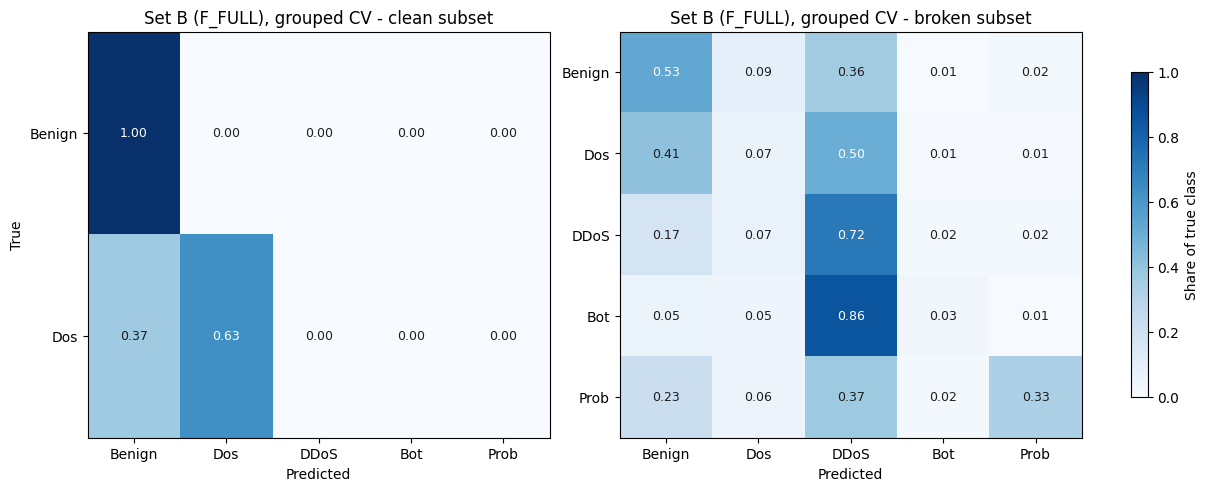

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True,
                         gridspec_kw={'width_ratios': [1, 1]})
for ax, cm, title in zip(axes, [cm_clean, cm_broken], ['clean subset', 'broken subset']):
    image = ax.imshow(cm.to_numpy(), cmap='Blues', vmin=0, vmax=1, aspect='auto')
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            value = cm.iloc[i, j]
            ax.text(j, i, f'{value:.2f}', ha='center', va='center',
                    color='white' if value > 0.5 else '#1d1d1f', fontsize=9)
    ax.set_xticks(range(cm.shape[1]))
    ax.set_xticklabels(cm.columns)
    ax.set_yticks(range(cm.shape[0]))
    ax.set_yticklabels(cm.index)
    ax.set_xlabel('Predicted')
    ax.set_title('Set B (F_FULL), grouped CV - ' + title)
axes[0].set_ylabel('True')
fig.colorbar(image, ax=axes, shrink=0.8, label='Share of true class')
plt.show()

## 12. Comment
On session-grouped CV, the best 5-class configurations reached a macro F1 of about 0.50 (Set B 0.499 ± 0.052, subset models 0.504 ± 0.045), against 0.418 ± 0.119 for E0; their broken-subset F1 stayed between 0.324 and 0.343, so the gain we measured comes mostly from the clean subset (Dos). In the broken subset, Set B predicted DDoS for 86% of the Bot rows and for about half of the broken Dos rows; Bot recall stayed at 0.03 except with E9 (0.29), which lowered DDoS recall at the same time. Random folds gave 0.12-0.25 higher macro F1 than grouped folds on the same rows, which is about the size of the gap between this table and the earlier single random split (0.67). The binary task reached 0.817 ± 0.058 on grouped CV; these numbers were chosen and reported on the same folds, so they are slightly optimistic (section 1), and the prediction time per flow was a few microseconds on this machine for every configuration.